## Этап 1. Окружение и запуск

In [1]:
!pip install -r requirements.txt

ERROR: Could not install packages due to an OSError: [WinError 5] Отказано в доступе: 'c:\\programdata\\anaconda3\\lib\\site-packages\\__pycache__\\typing_extensions.cpython-39.pyc'
Consider using the `--user` option or check the permissions.




  Using cached pandas-2.3.3-cp39-cp39-win_amd64.whl (11.4 MB)
  Using cached numpy-2.0.2-cp39-cp39-win_amd64.whl (15.9 MB)
  Using cached openpyxl-3.1.5-py2.py3-none-any.whl (250 kB)
  Using cached jupyterlab-4.5.11-py3-none-any.whl (12.5 MB)
  Using cached matplotlib-3.9.4-cp39-cp39-win_amd64.whl (7.8 MB)
  Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
  Using cached tzdata-2026.5-py2.py3-none-any.whl (347 kB)
  Using cached typing_extensions-4.16.0-py3-none-any.whl (45 kB)
  Using cached jinja2-3.1.6-py3-none-any.whl (134 kB)


In [2]:
!python src/prepare_model_data.py

  Using cached httpx-0.28.1-py3-none-any.whl (73 kB)
  Using cached packaging-26.3-py3-none-any.whl (129 kB)
  Using cached tomli-2.5.0-py3-none-any.whl (14 kB)
  Using cached async_lru-2.0.5-py3-none-any.whl (6.1 kB)
  Using cached jupyterlab_server-2.28.0-py3-none-any.whl (59 kB)
  Using cached jupyter_server-2.18.2-py3-none-any.whl (391 kB)
  Using cached tornado-6.5.10-cp39-abi3-win_amd64.whl (468 kB)
  Using cached jupyter_lsp-2.3.1-py3-none-any.whl (77 kB)
  Using cached importlib_metadata-8.7.1-py3-none-any.whl (27 kB)
  Using cached ipykernel-6.31.0-py3-none-any.whl (117 kB)
  Using cached notebook_shim-0.2.4-py3-none-any.whl (13 kB)
  Using cached importlib_resources-6.5.2-py3-none-any.whl (37 kB)
  Using cached contourpy-1.3.0-cp39-cp39-win_amd64.whl (211 kB)
  Using cached httpcore-1.0.9-py3-none-any.whl (78 kB)
  Using cached h11-0.16.0-py3-none-any.whl (37 kB)
  Using cached zipp-3.23.1-py3-none-any.whl (10 kB)
  Using cached comm-0.2.3-py3-none-any.whl (7.3 kB)
  Using ca

 1. Газпром Поляна           73.8
 2. Красная Поляна           71.7
 3. Роза Хутор               71.6
 4. Сорочаны                 70.1
 5. Архыз                    59.3
 6. Домбай                   57.3
 7. Игора                    55.9
 8. Шерегеш                  55.7
 9. Горный воздух            52.8
10. Бобровый лог             51.1
11. Губаха                   50.7
12. Эльбрус                  49.0


## Этап 2: Аудит данных.

In [3]:
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Настройка отображения таблиц в Jupyter (чтобы видеть все колонки)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
print("Библиотеки успешно загружены!")

Библиотеки успешно загружены!


In [4]:
# Загружаем исходный справочник курортов
with open('data/raw/resorts.json', 'r', encoding='utf-8') as f:
    raw_resorts = json.load(f)

# Превращаем в таблицу (первая строка - это заголовки)
df_resorts = pd.DataFrame(raw_resorts[1:], columns=raw_resorts[0])

print(f"Размер таблицы курортов: {df_resorts.shape[0]} строк, {df_resorts.shape[1]} колонок")
print(f"Уникальных resort_id: {df_resorts['resort_id'].nunique()}")

# Смотрим первые 5 строк, чтобы понять структуру
df_resorts.head()

Размер таблицы курортов: 32 строк, 33 колонок
Уникальных resort_id: 32


,resort_id,name_ru,region,latitude,longitude,coordinate_quality,coordinate_source_title,coordinate_source_url,wikidata_id,piste_segments_6km,lift_lines_6km,lodging_objects_6km,food_objects_6km,transport_objects_6km,attraction_objects_6km,osm_radius_km,osm_overlap_warning,open_meteo_elevation_m,winter_mean_temperature_c,avg_snowfall_cm_per_season,avg_freezing_days_per_season,avg_snow_days_per_season,max_daily_snowfall_cm,weather_model,weather_period_start,weather_period_end,nearest_scheduled_airport,nearest_airport_iata,nearest_airport_distance_km,nearest_airport_municipality,completeness_pct,quality_flags,collected_at
0,R001,Роза Хутор,Краснодарский край,43.646390,40.332220,nearby_feature_proxy,Роза Хутор,https://ru.wikipedia.org/wiki/%D0%A0%D0%BE%D0%...,Q1335490,334,64,86,107,45,42,6,"Possible overlap with Газпром Поляна (6.0 km),...",950,4.272848,390.082,35.2,92.6,47.67,ERA5,2021-11-01,2026-04-30,Sochi International Airport,AER,37.3,Sochi,1.0,coordinates are proxy; OSM radii overlap,46279.509709
1,R002,Красная Поляна,Краснодарский край,43.686110,40.260000,resort_or_complex_page,Красная Поляна (курорт),https://ru.wikipedia.org/wiki/%D0%9A%D1%80%D0%...,Q120478823,121,44,255,259,76,82,6,"Possible overlap with Газпром Поляна (1.6 km),...",513,7.114349,390.082,16.8,92.6,47.67,ERA5,2021-11-01,2026-04-30,Sochi International Airport,AER,35.9,Sochi,1.0,OSM radii overlap,46279.509709
2,R003,Газпром Поляна,Краснодарский край,43.684519,40.280172,resort_or_complex_page,Курорт Газпрома,https://ru.wikipedia.org/wiki/%D0%9A%D1%83%D1%...,Q4144556,240,63,223,243,77,77,6,"Possible overlap with Красная Поляна (1.6 km),...",546,6.900331,390.082,18.6,92.6,47.67,ERA5,2021-11-01,2026-04-30,Sochi International Airport,AER,36.9,Sochi,1.0,OSM radii overlap,46279.509709
3,R004,Шерегеш,Кемеровская область,52.953380,87.955480,resort_or_complex_page,Шерегеш (горнолыжный курорт),https://ru.wikipedia.org/wiki/%D0%A8%D0%B5%D1%...,Q21645716,142,23,233,57,54,4,6,None,695,-9.152539,243.922,151.6,93.2,21.07,ERA5,2021-11-01,2026-04-30,Spichenkovo Airport,NOZ,119.2,Novokuznetsk,1.0,None,46279.509709
4,R005,Архыз,Карачаево-Черкесская Республика,43.543330,41.181670,resort_or_complex_page,Архыз (курорт),https://ru.wikipedia.org/wiki/%D0%90%D1%80%D1%...,Q4127579,42,13,187,69,18,25,6,None,1655,0.470088,523.194,81.6,107.6,29.47,ERA5,2021-11-01,2026-04-30,Sochi International Airport,AER,99.4,Sochi,1.0,None,46279.509709


In [5]:
# Загружаем готовую витрину с рассчитанным рейтингом
with open('data/processed/model_data.json', 'r', encoding='utf-8') as f:
    model_data = json.load(f)

# Смотрим, какие ключи есть в JSON
print("Ключи в файле model_data.json:", list(model_data.keys()))

# Превращаем итоговый рейтинг в таблицу
df_model = pd.DataFrame(model_data['model_rows'])

print(f"\nРазмер итогового рейтинга: {df_model.shape[0]} строк, {df_model.shape[1]} колонок")
print(f"Уникальных resort_id в рейтинге: {df_model['resort_id'].nunique()}")

# Выводим топ-5 курортов по индексу с их уверенностью (confidence_score)
df_model[['rank_default', 'name_ru', 'popularity_score_default', 'confidence_score']].head(5)

Ключи в файле model_data.json: ['weights', 'regions', 'resorts', 'model_rows']

Размер итогового рейтинга: 32 строк, 43 колонок
Уникальных resort_id в рейтинге: 32


,rank_default,name_ru,popularity_score_default,confidence_score
0,1,Газпром Поляна,73.788787,100.0
1,2,Красная Поляна,71.687850,100.0
2,3,Роза Хутор,71.569843,75.0
3,4,Сорочаны,70.143513,75.0
4,5,Архыз,59.250873,100.0


In [6]:
# Превращаем региональные данные в таблицу
df_regions = pd.DataFrame(model_data['regions'])

print(f"Уникальных регионов: {df_regions['region'].nunique()}")

# Проверяем, есть ли пропуски в количестве поездок за 2025 год
missing_trips = df_regions[df_regions['trips_2025'].isnull()]
print(f"Регионов без данных о поездках за 2025: {len(missing_trips)}")

# Проверяем рост и длительность пребывания
print(f"Регионов без данных о росте: {df_regions['trips_growth_2025'].isnull().sum()}")
print(f"Регионов без данных о длительности: {df_regions['avg_stay_nights_2025'].isnull().sum()}")

Уникальных регионов: 20
Регионов без данных о поездках за 2025: 0
Регионов без данных о росте: 0
Регионов без данных о длительности: 0


## Этапу 3: Изучение методики расчетов.

In [7]:
# Выводим веса показателей
weights = model_data['weights']
print("Веса показателей (в сумме должны давать 100):")
for metric, weight in weights.items():
    print(f" - {metric}: {weight}")
print(f"\nСумма весов: {sum(weights.values())}")

Веса показателей (в сумме должны давать 100):
 - region_trips: 25.0
 - region_growth: 10.0
 - avg_stay: 5.0
 - pistes: 10.0
 - lifts: 7.0
 - lodging: 5.0
 - amenities: 3.0
 - snow_days: 8.0
 - freezing_days: 6.0
 - snowfall: 6.0
 - airport: 8.0
 - transport: 2.0
 - price: 5.0

Сумма весов: 100.0


In [8]:
# Берем данные курорта с 1-м местом (Газпром Поляна)
top_resort = df_model.iloc[0]

# Список всех 13 баллов
score_columns = [
    'region_trips_score', 'region_growth_score', 'avg_stay_score', 
    'pistes_score', 'lifts_score', 'lodging_score', 'amenities_score', 
    'snow_days_score', 'freezing_days_score', 'snowfall_score', 
    'airport_score', 'transport_score', 'price_score'
]

print(f"Курорт: {top_resort['name_ru']}")
print(f"Итоговый индекс: {top_resort['popularity_score_default']:.2f}\n")
print("Баллы по каждому из 13 показателей (от 0 до 100):")

# Выводим только баллы и округляем до 1 знака
print(top_resort[score_columns].astype(float).round(1))

Курорт: Газпром Поляна
Итоговый индекс: 73.79

Баллы по каждому из 13 показателей (от 0 до 100):
region_trips_score     95.8
region_growth_score    42.3
avg_stay_score         83.4
pistes_score           94.3
lifts_score            99.6
lodging_score          97.6
amenities_score        98.9
snow_days_score        69.1
freezing_days_score     1.2
snowfall_score         81.7
airport_score          40.3
transport_score        71.5
price_score            40.3
Name: 0, dtype: float64


In [9]:
# Словарь соответствия: колонка с баллом -> ключ веса
score_to_weight = {
    'region_trips_score': 'region_trips',
    'region_growth_score': 'region_growth',
    'avg_stay_score': 'avg_stay',
    'pistes_score': 'pistes',
    'lifts_score': 'lifts',
    'lodging_score': 'lodging',
    'amenities_score': 'amenities',
    'snow_days_score': 'snow_days',
    'freezing_days_score': 'freezing_days',
    'snowfall_score': 'snowfall',
    'airport_score': 'airport',
    'transport_score': 'transport',
    'price_score': 'price'
}

total_calculated = 0
print("Вклад каждого показателя в итоговый балл (Балл * Вес / 100):")

for score_col, weight_key in score_to_weight.items():
    score = float(top_resort[score_col])
    weight = weights[weight_key]
    contribution = (score * weight) / 100
    total_calculated += contribution
    print(f" - {weight_key:<15}: {score:5.1f} * {weight:4.1f} / 100 = {contribution:4.2f}")

print(f"\nСумма вкладов (должна быть равна итоговому индексу): {total_calculated:.4f}")
print(f"Итоговый индекс из файла: {top_resort['popularity_score_default']:.4f}")

Вклад каждого показателя в итоговый балл (Балл * Вес / 100):
 - region_trips   :  95.8 * 25.0 / 100 = 23.96
 - region_growth  :  42.3 * 10.0 / 100 = 4.23
 - avg_stay       :  83.4 *  5.0 / 100 = 4.17
 - pistes         :  94.3 * 10.0 / 100 = 9.43
 - lifts          :  99.6 *  7.0 / 100 = 6.97
 - lodging        :  97.6 *  5.0 / 100 = 4.88
 - amenities      :  98.9 *  3.0 / 100 = 2.97
 - snow_days      :  69.1 *  8.0 / 100 = 5.53
 - freezing_days  :   1.2 *  6.0 / 100 = 0.07
 - snowfall       :  81.7 *  6.0 / 100 = 4.90
 - airport        :  40.3 *  8.0 / 100 = 3.22
 - transport      :  71.5 *  2.0 / 100 = 1.43
 - price          :  40.3 *  5.0 / 100 = 2.01

Сумма вкладов (должна быть равна итоговому индексу): 73.7888
Итоговый индекс из файла: 73.7888


In [10]:
# Выведем 5 курортов с самым высоким индексом и их уверенность
print("Топ-10: Индекс vs Уверенность")
for index, row in df_model.head(10).iterrows():
    print(f"{row['rank_default']:>2}. {row['name_ru']:<20} Индекс: {row['popularity_score_default']:.1f} | Уверенность: {row['confidence_score']:.1f}")

Топ-10: Индекс vs Уверенность
 1. Газпром Поляна       Индекс: 73.8 | Уверенность: 100.0
 2. Красная Поляна       Индекс: 71.7 | Уверенность: 100.0
 3. Роза Хутор           Индекс: 71.6 | Уверенность: 75.0
 4. Сорочаны             Индекс: 70.1 | Уверенность: 75.0
 5. Архыз                Индекс: 59.3 | Уверенность: 100.0
 6. Домбай               Индекс: 57.3 | Уверенность: 75.0
 7. Игора                Индекс: 55.9 | Уверенность: 50.0
 8. Шерегеш              Индекс: 55.7 | Уверенность: 75.0
 9. Горный воздух        Индекс: 52.8 | Уверенность: 45.5
10. Бобровый лог         Индекс: 51.1 | Уверенность: 45.5


## Этап 4: Написание тестов.

In [11]:
print("Запуск автоматических проверок по ТЗ (Раздел 16)...\n")

# 1. Сумма весов равна 100 (с погрешностью 0.001)
assert abs(sum(weights.values()) - 100.0) < 0.001, "❌ Ошибка: Сумма весов не равна 100!"
print("✅ Тест 1: Сумма весов равна 100")

# 2. Каждый нормированный балл в диапазоне от 0 до 100
score_cols = [col for col in df_model.columns if col.endswith('_score')]
for col in score_cols:
    # Используем round(5), чтобы убрать хвосты float (например, 100.00000000000001)
    assert df_model[col].round(5).between(0, 100).all(), f"❌ Ошибка: Баллы в колонке {col} выходят за пределы 0-100!"
print("✅ Тест 2: Все 13 баллов лежат в диапазоне от 0 до 100")

# 3. Итоговый индекс и confidence_score находятся в диапазоне 0-100
assert df_model['popularity_score_default'].round(5).between(0, 100).all(), "❌ Ошибка: Индекс вне 0-100!"
assert df_model['confidence_score'].round(5).between(0, 100).all(), "❌ Ошибка: Уверенность вне 0-100!"
print("✅ Тест 3: Итоговый индекс и confidence_score в диапазоне 0-100")

# 4. В таблице 32 строки и 32 уникальных resort_id
assert len(df_model) == 32, "❌ Ошибка: В таблице не 32 строки!"
assert df_model['resort_id'].nunique() == 32, "❌ Ошибка: Не 32 уникальных resort_id!"
print("✅ Тест 4: В таблице 32 строки и 32 уникальных resort_id")

# 5. После регионального соединения нет пропусков в trips_2025
assert df_model['trips_2025'].notnull().all(), "❌ Ошибка: Есть пропуски в trips_2025!"
print("✅ Тест 5: После соединения нет пропусков в trips_2025")

# 6. В итоговых таблицах нет бесконечностей
numeric_cols = df_model.select_dtypes(include=[np.number]).columns
assert not np.isinf(df_model[numeric_cols]).any().any(), "❌ Ошибка: В данных есть бесконечности (inf)!"
print("✅ Тест 6: В итоговых таблицах нет бесконечностей")

print("\nВсе автоматические проверки из ТЗ пройдены успешно!")

Запуск автоматических проверок по ТЗ (Раздел 16)...

✅ Тест 1: Сумма весов равна 100
✅ Тест 2: Все 13 баллов лежат в диапазоне от 0 до 100
✅ Тест 3: Итоговый индекс и confidence_score в диапазоне 0-100
✅ Тест 4: В таблице 32 строки и 32 уникальных resort_id
✅ Тест 5: После соединения нет пропусков в trips_2025
✅ Тест 6: В итоговых таблицах нет бесконечностей

Все автоматические проверки из ТЗ пройдены успешно!


## Этап 5: Сценарии весов.

**1. Базовый (текущий).**  

**2. Климат +20% (увеличиваем важность снега, мороза и снегопада, а остальные веса немного уменьшаем, чтобы сумма осталась 100).**  

**3. Доступность +20% (увеличиваем важность аэропорта и транспорта, остальные уменьшаем).**  

### 5.1. Код для сценариев

In [12]:
# 1. Задаем базовые веса (из нашего словаря weights)
w_base = weights.copy()

# 2. Сценарий "Климат +20%"
# Климат = snow_days (8) + freezing_days (6) + snowfall (6) = 20. 
# Увеличиваем каждый на 20%. Новый вес климата = 24.
# Остальные 80 весов уменьшаем пропорционально (умножаем на 76/80 = 0.95)
w_climate = w_base.copy()
w_climate['snow_days'] *= 1.2
w_climate['freezing_days'] *= 1.2
w_climate['snowfall'] *= 1.2
for k in w_climate:
    if k not in ['snow_days', 'freezing_days', 'snowfall']:
        w_climate[k] *= 0.95

# 3. Сценарий "Доступность +20%"
# Доступность = airport (8) + transport (2) = 10. 
# Увеличиваем каждый на 20%. Новый вес = 12.
# Остальные 90 весов уменьшаем пропорционально (умножаем на 88/90)
w_access = w_base.copy()
w_access['airport'] *= 1.2
w_access['transport'] *= 1.2
for k in w_access:
    if k not in ['airport', 'transport']:
        w_access[k] *= (88.0 / 90.0)

# Проверяем, что новые суммы весов тоже равны 100
print(f"Сумма базовых весов: {sum(w_base.values()):.2f}")
print(f"Сумма весов (Климат): {sum(w_climate.values()):.2f}")
print(f"Сумма весов (Доступность): {sum(w_access.values()):.2f}\n")

Сумма базовых весов: 100.00
Сумма весов (Климат): 100.00
Сумма весов (Доступность): 100.00



### 5.2. Пересчитываем рейтинги и сравниваем

In [13]:
# Функция для расчета нового индекса
def calculate_new_score(row, weights_dict):
    total = 0
    for score_col, weight_key in score_to_weight.items():
        total += float(row[score_col]) * weights_dict[weight_key]
    return total / 100.0

# Считаем индексы для трех сценариев
df_model['score_base'] = df_model.apply(lambda row: calculate_new_score(row, w_base), axis=1)
df_model['score_climate'] = df_model.apply(lambda row: calculate_new_score(row, w_climate), axis=1)
df_model['score_access'] = df_model.apply(lambda row: calculate_new_score(row, w_access), axis=1)

# Определяем новые места (ранги)
df_model['rank_climate'] = df_model['score_climate'].rank(ascending=False, method='min').astype(int)
df_model['rank_access'] = df_model['score_access'].rank(ascending=False, method='min').astype(int)

# Считаем изменение позиций (положительное значение = курорт поднялся, отрицательное = упал)
df_model['delta_climate'] = df_model['rank_default'] - df_model['rank_climate']
df_model['delta_access'] = df_model['rank_default'] - df_model['rank_access']

print("ТОП-5 курортов по сценарию 'Климат +20%':")
display(df_model.sort_values('rank_climate')[['name_ru', 'rank_default', 'rank_climate', 'delta_climate']].head(5))

print("\nКто сильнее всего взлетел/упал при усилении климата:")
print("🔺 Взлетели:")
display(df_model[df_model['delta_climate'] > 0].sort_values('delta_climate', ascending=False)[['name_ru', 'rank_default', 'rank_climate', 'delta_climate']].head(3))
print("🔻 Упали:")
display(df_model[df_model['delta_climate'] < 0].sort_values('delta_climate')[['name_ru', 'rank_default', 'rank_climate', 'delta_climate']].head(3))

ТОП-5 курортов по сценарию 'Климат +20%':


,name_ru,rank_default,rank_climate,delta_climate
0,Газпром Поляна,1,1,0
2,Роза Хутор,3,2,1
1,Красная Поляна,2,3,-1
3,Сорочаны,4,4,0
4,Архыз,5,5,0



Кто сильнее всего взлетел/упал при усилении климата:
🔺 Взлетели:


,name_ru,rank_default,rank_climate,delta_climate
23,Кукисвумчорр,24,22,2
2,Роза Хутор,3,2,1
7,Шерегеш,8,7,1


🔻 Упали:


,name_ru,rank_default,rank_climate,delta_climate
21,Солнечная долина,22,24,-2
1,Красная Поляна,2,3,-1
6,Игора,7,8,-1


### 5.3. Смотрим эффект для доступности

In [14]:
print("ТОП-5 курортов по сценарию 'Доступность +20%':")
display(df_model.sort_values('rank_access')[['name_ru', 'rank_default', 'rank_access', 'delta_access']].head(5))

print("\nКто сильнее всего взлетел/упал при усилении доступности:")
print("🔺 Взлетели (близко к аэропортам):")
display(df_model[df_model['delta_access'] > 0].sort_values('delta_access', ascending=False)[['name_ru', 'rank_default', 'rank_access', 'delta_access']].head(3))
print("🔻 Упали (далеко от аэропортов):")
display(df_model[df_model['delta_access'] < 0].sort_values('delta_access')[['name_ru', 'rank_default', 'rank_access', 'delta_access']].head(3))

ТОП-5 курортов по сценарию 'Доступность +20%':


,name_ru,rank_default,rank_access,delta_access
0,Газпром Поляна,1,1,0
1,Красная Поляна,2,2,0
2,Роза Хутор,3,3,0
3,Сорочаны,4,4,0
4,Архыз,5,5,0



Кто сильнее всего взлетел/упал при усилении доступности:
🔺 Взлетели (близко к аэропортам):


,name_ru,rank_default,rank_access,delta_access
12,Морозная гора,13,12,1
18,Абзаково,19,18,1
22,Красная Глинка,23,22,1


🔻 Упали (далеко от аэропортов):


,name_ru,rank_default,rank_access,delta_access
11,Эльбрус,12,13,-1
17,Соболиная гора,18,19,-1
21,Солнечная долина,22,23,-1


## Этап 6: Анализ факторов.

### 6.1. Топ-3 показателя, влияющих на порядок

Средний вклад показателей в итоговый индекс (Топ-5):
 - region_trips: 10.68 балла
 - pistes: 5.09 балла
 - region_growth: 4.62 балла
 - snow_days: 4.53 балла
 - freezing_days: 4.11 балла


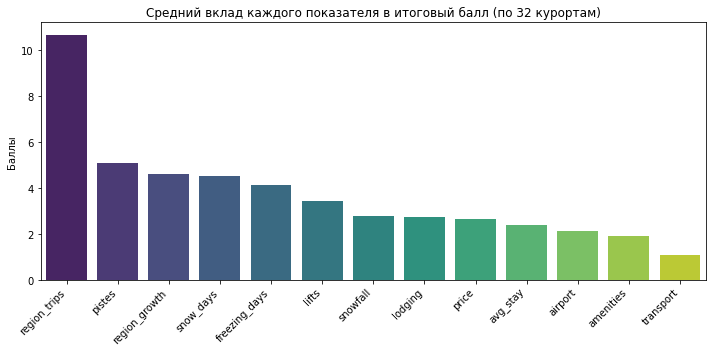

In [15]:
# Считаем средний вклад каждого показателя в балл по всем 32 курортам
contributions = {}
for score_col, weight_key in score_to_weight.items():
    # Вклад = Балл курорта * Вес / 100
    avg_contribution = (df_model[score_col] * weights[weight_key] / 100).mean()
    contributions[weight_key] = avg_contribution

# Сортируем по убыванию
sorted_contrib = dict(sorted(contributions.items(), key=lambda item: item[1], reverse=True))

print("Средний вклад показателей в итоговый индекс (Топ-5):")
for k, v in list(sorted_contrib.items())[:5]:
    print(f" - {k}: {v:.2f} балла")

# Строим график
plt.figure(figsize=(10, 5))
sns.barplot(x=list(sorted_contrib.keys()), y=list(sorted_contrib.values()), palette="viridis")
plt.xticks(rotation=45, ha='right')
plt.title("Средний вклад каждого показателя в итоговый балл (по 32 курортам)")
plt.ylabel("Баллы")
plt.tight_layout()
plt.show()

### 6.2. Кто высоко за счет спроса, а кто за счет инфраструктуры

In [16]:
# Считаем суммы вкладов по группам для каждого курорта
def get_group_contributions(row):
    demand = (row['region_trips_score'] * w_base['region_trips'] + 
              row['region_growth_score'] * w_base['region_growth'] + 
              row['avg_stay_score'] * w_base['avg_stay']) / 100
    
    infra = (row['pistes_score'] * w_base['pistes'] + 
             row['lifts_score'] * w_base['lifts'] + 
             row['lodging_score'] * w_base['lodging'] + 
             row['amenities_score'] * w_base['amenities']) / 100
             
    climate = (row['snow_days_score'] * w_base['snow_days'] + 
               row['freezing_days_score'] * w_base['freezing_days'] + 
               row['snowfall_score'] * w_base['snowfall']) / 100
               
    return pd.Series([demand, infra, climate])

df_model[['contrib_demand', 'contrib_infra', 'contrib_climate']] = df_model.apply(get_group_contributions, axis=1)

# Выводим топ-3 по каждому фактору
print("Топ-3 курорта по вкладу РЕГИОНАЛЬНОГО СПРОСА:")
display(df_model.sort_values('contrib_demand', ascending=False)[['name_ru', 'contrib_demand']].head(3))

print("\nТоп-3 курорта по вкладу ИНФРАСТРУКТУРЫ:")
display(df_model.sort_values('contrib_infra', ascending=False)[['name_ru', 'contrib_infra']].head(3))

print("\nТоп-3 курорта по вкладу КЛИМАТА:")
display(df_model.sort_values('contrib_climate', ascending=False)[['name_ru', 'contrib_climate']].head(3))

Топ-3 курорта по вкладу РЕГИОНАЛЬНОГО СПРОСА:


,name_ru,contrib_demand
3,Сорочаны,37.660177
0,Газпром Поляна,32.364727
2,Роза Хутор,32.364727



Топ-3 курорта по вкладу ИНФРАСТРУКТУРЫ:


,name_ru,contrib_infra
0,Газпром Поляна,24.254580
2,Роза Хутор,23.603085
1,Красная Поляна,22.646030



Топ-3 курорта по вкладу КЛИМАТА:


,name_ru,contrib_climate
12,Морозная гора,16.344018
23,Кукисвумчорр,16.292603
5,Домбай,16.216954


### 6.3. Высокий индекс + низкая уверенность

In [17]:
# Фильтруем: индекс > 45 (условно высокий) и уверенность < 60
risky_resorts = df_model[(df_model['popularity_score_default'] > 45) & (df_model['confidence_score'] < 60)]

print("Курорты с высоким индексом, но низкой уверенностью в данных:")
display(risky_resorts[['name_ru', 'popularity_score_default', 'confidence_score', 'quality_flags']])

Курорты с высоким индексом, но низкой уверенностью в данных:


,name_ru,popularity_score_default,confidence_score,quality_flags
6,Игора,55.931923,50.000000,coordinates are proxy
8,Горный воздух,52.786718,45.454545,check coordinates
9,Бобровый лог,51.092041,45.454545,check coordinates
10,Губаха,50.689746,45.454545,check coordinates
12,Морозная гора,48.856709,45.454545,check coordinates
14,Чегет,47.645391,50.000000,coordinates are proxy; OSM radii overlap
15,Аджигардак,46.968475,45.454545,check coordinates
16,КолаСпортЛэнд,45.713792,45.454545,check coordinates; OSM radii overlap
17,Соболиная гора,45.322960,45.454545,check coordinates
18,Абзаково,45.276811,45.454545,check coordinates


### Шаг 6.4. Пересечение OSM (Пары соседних курортов)

In [18]:
# Ищем курорты, у которых во флагах есть упоминание пересечения (OSM radii overlap)
overlap_resorts = df_model[df_model['quality_flags'].str.contains('OSM radii overlap', na=False)]

print("Курорты с возможным пересечением радиусов OSM (6 км):")
for idx, row in overlap_resorts.iterrows():
    print(f" - {row['name_ru']}: {row['quality_flags']}")

Курорты с возможным пересечением радиусов OSM (6 км):
 - Газпром Поляна: OSM radii overlap
 - Красная Поляна: OSM radii overlap
 - Роза Хутор: coordinates are proxy; OSM radii overlap
 - Эльбрус: coordinates are proxy; OSM radii overlap
 - Большой Вудъявр: check coordinates; OSM radii overlap
 - Чегет: coordinates are proxy; OSM radii overlap
 - КолаСпортЛэнд: check coordinates; OSM radii overlap
 - Кукисвумчорр: check coordinates; OSM radii overlap
 - Мамисон: coordinates are proxy; OSM radii overlap
 - Цей: coordinates are proxy; OSM radii overlap


### 6.5. Влияние расширенных данных Росстата

In [19]:
# Загружаем данные Росстата
with open('data/processed/rosstat_enrichment.json', 'r', encoding='utf-8') as f:
    rosstat_data = json.load(f)

df_rosstat = pd.DataFrame(rosstat_data['records'])

# Соединяем наш рейтинг с Росстатом по названию региона
df_merged = pd.merge(df_model, df_rosstat[['region', 'ksr_persons_2025']], on='region', how='left')

# Посмотрим на топ-10 по индексу и сколько у них размещенных лиц в регионе
print("Топ-10 курортов и количество размещенных лиц в их регионе (КСР 2025):")
display(df_merged[['name_ru', 'popularity_score_default', 'region', 'ksr_persons_2025']].head(10))

Топ-10 курортов и количество размещенных лиц в их регионе (КСР 2025):


,name_ru,popularity_score_default,region,ksr_persons_2025
0,Газпром Поляна,73.788787,Краснодарский край,9501255.0
1,Красная Поляна,71.687850,Краснодарский край,9501255.0
2,Роза Хутор,71.569843,Краснодарский край,9501255.0
3,Сорочаны,70.143513,Московская область,5641768.0
4,Архыз,59.250873,Карачаево-Черкесская Республика,314333.0
5,Домбай,57.315487,Карачаево-Черкесская Республика,314333.0
6,Игора,55.931923,Ленинградская область,1537639.0
7,Шерегеш,55.657061,Кемеровская область,817583.0
8,Горный воздух,52.786718,Сахалинская область,255911.0
9,Бобровый лог,51.092041,Красноярский край,1191057.0


## 7: Формируем итоговую витрину resort_scores

In [20]:
# 1. Добавляем компоненты (Спрос, Инфраструктура, Зима, Доступность, Цена)
df_model['component_demand'] = df_model['contrib_demand']
df_model['component_infra'] = df_model['contrib_infra']
df_model['component_climate'] = df_model['contrib_climate']
df_model['component_access'] = (df_model['airport_score'] * w_base['airport'] + df_model['transport_score'] * w_base['transport']) / 100
df_model['component_price'] = (df_model['price_score'] * w_base['price']) / 100

# 2. Формируем финальный список колонок по ТЗ (Раздел 1)
columns_for_mart = [
    'resort_id', 'name_ru', 'region',
    # Исходные показатели
    'trips_2025', 'trips_growth_2025', 'avg_stay_nights_2025', 
    'piste_segments_6km', 'lift_lines_6km', 'lodging_objects_6km', 
    'avg_snow_days_per_season', 'avg_freezing_days_per_season', 'avg_snowfall_cm_per_season',
    'nearest_airport_distance_km', 'transport_objects_6km', 'adult_skipass_avg_rub',
    # Баллы (13 штук)
    'region_trips_score', 'region_growth_score', 'avg_stay_score', 
    'pistes_score', 'lifts_score', 'lodging_score', 'amenities_score',
    'snow_days_score', 'freezing_days_score', 'snowfall_score', 
    'airport_score', 'transport_score', 'price_score',
    # Компоненты (5 штук)
    'component_demand', 'component_infra', 'component_climate', 'component_access', 'component_price',
    # Итоговые поля
    'popularity_score_default', 'rank_default', 'confidence_score', 'quality_flags'
]

# Создаем финальную таблицу и переименовываем колонки
df_final = df_model[columns_for_mart].copy()
df_final = df_final.rename(columns={
    'popularity_score_default': 'popularity_score',
    'rank_default': 'rank'
}).sort_values('rank')

# Сохраняем в CSV 
import os
os.makedirs('data/mart', exist_ok=True) # Создаем папку, если ее нет
df_final.to_csv('data/mart/resort_scores.csv', index=False, encoding='utf-8-sig')
print("✅ Таблица resort_scores сохранена в data/mart/resort_scores.csv")
print(f"Размер таблицы: {df_final.shape[0]} строк, {df_final.shape[1]} колонок")

# Смотрим первые 3 строки
display(df_final[['rank', 'name_ru', 'popularity_score', 'confidence_score']].head(3))

✅ Таблица resort_scores сохранена в data/mart/resort_scores.csv
Размер таблицы: 32 строк, 37 колонок


,rank,name_ru,popularity_score,confidence_score
0,1,Газпром Поляна,73.788787,100.0
1,2,Красная Поляна,71.687850,100.0
2,3,Роза Хутор,71.569843,75.0


In [21]:
# 1. Берем координаты из исходного справочника курортов
# (df_final у нас уже есть, df_resorts тоже загружен в начале)
coords = df_resorts[['resort_id', 'latitude', 'longitude']]

# 2. Объединяем финальный рейтинг с координатами
df_final_map = pd.merge(df_final, coords, on='resort_id', how='left')

# 3. Пересохраняем файл с новыми колонками
df_final_map.to_csv('data/mart/resort_scores.csv', index=False, encoding='utf-8-sig')

print("✅ Файл обновлен: добавлены колонки latitude и longitude")
print(f"Размер таблицы: {df_final_map.shape[0]} строк, {df_final_map.shape[1]} колонок")

# 4. Проверим, что координаты появились
display(df_final_map[['name_ru', 'latitude', 'longitude', 'popularity_score']].head(3))

✅ Файл обновлен: добавлены колонки latitude и longitude
Размер таблицы: 32 строк, 39 колонок


,name_ru,latitude,longitude,popularity_score
0,Газпром Поляна,43.684519,40.280172,73.788787
1,Красная Поляна,43.686110,40.260000,71.687850
2,Роза Хутор,43.646390,40.332220,71.569843
